# Backpropagation in Multilayer Neural Networks

### Goals:
- implementING a real gradient descent in `Numpy`

### Dataset:
- [sklearn.datasets.load_digits](http://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits)

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits

digits = load_digits()

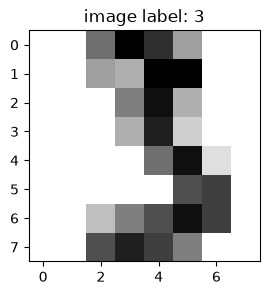

In [2]:
sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(digits.images[sample_index], cmap=plt.cm.gray_r,
           interpolation='nearest')
plt.title("image label: %d" % digits.target[sample_index]);

### Preprocessing

- Normalization
- Train / test split

In [3]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

data = np.asarray(digits.data, dtype='float32')
target = np.asarray(digits.target, dtype='int32')

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.15, random_state=37)

# mean = 0 ; standard deviation = 1.0
scaler = preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# print(scaler.mean_)
# print(scaler.scale_)

In [4]:
X_train.shape

(1527, 64)

In [5]:
X_train.dtype

dtype('float32')

In [6]:
X_test.shape

(270, 64)

In [7]:
y_train.shape

(1527,)

In [8]:
y_train.dtype

dtype('int32')

# Numpy Implementation

## a) Logistic Regression

In this section we will implement a logistic regression model trainable with SGD using numpy. Here are the objectives:

- Implement a simple forward model with no hidden layer (equivalent to a logistic regression):
note: shape, transpose of W with regards to course
$y = softmax(\mathbf{W} \dot x + b)$

- Build a predict function which returns the most probable class given an input $x$

- Build an accuracy function for a batch of inputs $X$ and the corresponding expected outputs $y_{true}$

- Build a grad function which computes $\frac{d}{dW} -\log(softmax(W \dot x + b))$ for an $x$ and its corresponding expected output $y_{true}$ ; check that the gradients are well defined

- Build a train function which uses the grad function output to update $\mathbf{W}$ and $b$


### One-hot encoding for class label data

First let's define a helper function to compute the one hot encoding of an integer array for a fixed number of classes (similar to keras' `to_categorical`):

In [9]:
def one_hot(n_classes, y):
    return np.eye(n_classes)[y]

In [10]:
one_hot(n_classes=10, y=3)

array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])

In [11]:
one_hot(n_classes=10, y=[0, 4, 9, 1])

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]])

### The softmax function

Now let's implement the softmax vector function:

$$
softmax(\mathbf{x}) = \frac{1}{\sum_{i=1}^{n}{e^{x_i}}}
\cdot
\begin{bmatrix}
  e^{x_1}\\\\
  e^{x_2}\\\\
  \vdots\\\\
  e^{x_n}
\end{bmatrix}
$$

In [12]:
def softmax(X):
    # Naive version: works for a single vector of activations only
    X = np.asarray(X, dtype=np.float64)
    exp = np.exp(X)
    return exp / np.sum(exp)

Make sure that this works one vector at a time (and check that the components sum to one):

In [13]:
print(softmax([10, 2, -3]))

[9.99662391e-01 3.35349373e-04 2.25956630e-06]


Note that a naive implementation of softmax might not be able process a batch of activations in a single call:

In [14]:
X = np.array([[10, 2, -3],
              [-1, 5, -20]])
print(softmax(X))

[[9.92957576e-01 3.33100158e-04 2.24441121e-06]
 [1.65840803e-05 6.69049552e-03 9.29172262e-14]]


Here is a way to implement softmax that works both for an individual vector of activations and for a batch of activation vectors at once:

In [15]:
def softmax(X):
    X = np.asarray(X, dtype=np.float64)
    # Subtracting the max of each row does not change the result
    # (softmax is shift invariant) but avoids overflow in np.exp
    exp = np.exp(X - np.max(X, axis=-1, keepdims=True))
    return exp / np.sum(exp, axis=-1, keepdims=True)


print("softmax of a single vector:")
print(softmax([10, 2, -3]))

softmax of a single vector:
[9.99662391e-01 3.35349373e-04 2.25956630e-06]


Probabilities should sum to 1:

In [16]:
print(np.sum(softmax([10, 2, -3])))

1.0


In [17]:
print("sotfmax of 2 vectors:")
X = np.array([[10, 2, -3],
              [-1, 5, -20]])
print(softmax(X))

sotfmax of 2 vectors:
[[9.99662391e-01 3.35349373e-04 2.25956630e-06]
 [2.47262316e-03 9.97527377e-01 1.38536042e-11]]


The sum of probabilities for each input vector of logits should some to 1:

In [18]:
print(np.sum(softmax(X), axis=1))

[1. 1.]


Implement a function that given the true one-hot encoded class `Y_true` and and some predicted probabilities `Y_pred` returns the negative log likelihood.

In [19]:
EPSILON = 1e-8


def nll(Y_true, Y_pred):
    Y_true = np.asarray(Y_true)
    Y_pred = np.asarray(Y_pred)

    # -log of the probability given to the true class
    # (EPSILON avoids log(0) when a probability is exactly 0)
    return -np.sum(Y_true * np.log(Y_pred + EPSILON))


# Make sure that it works for a simple sample at a time
print(nll([1, 0, 0], [.99, 0.01, 0]))

0.01005032575249135


Check that the nll of a very confident yet bad prediction is a much higher positive number:

In [20]:
print(nll([1, 0, 0], [0.01, 0.01, .98]))

4.605169185988592


Make sure that your implementation can compute the average negative log likelihood of a group of predictions: `Y_pred` and `Y_true` can therefore be past as 2D arrays:

In [21]:
def nll(Y_true, Y_pred):
    Y_true = np.atleast_2d(Y_true)
    Y_pred = np.atleast_2d(Y_pred)

    # log-likelihood of each sample, then average over the batch
    loglikelihoods = np.sum(Y_true * np.log(Y_pred + EPSILON), axis=1)
    return -np.mean(loglikelihoods)

In [22]:
# Check that the average NLL of the following 3 almost perfect
# predictions is close to 0
Y_true = np.array([[0, 1, 0],
                   [1, 0, 0],
                   [0, 0, 1]])

Y_pred = np.array([[0,   1,    0],
                   [.99, 0.01, 0],
                   [0,   0,    1]])

print(nll(Y_true, Y_pred))

0.0033501019174971905


Let us now study the following linear model trainable by SGD, **one sample at a time**.

In [23]:
class LogisticRegression():

    def __init__(self, input_size, output_size):
        self.W = np.random.uniform(size=(input_size, output_size),
                                   high=0.1, low=-0.1)
        self.b = np.random.uniform(size=output_size,
                                   high=0.1, low=-0.1)
        self.output_size = output_size

    def forward(self, X):
        Z = np.dot(X, self.W) + self.b
        return softmax(Z)

    def predict(self, X):
        if len(X.shape) == 1:
            return np.argmax(self.forward(X))
        else:
            return np.argmax(self.forward(X), axis=1)

    def grad_loss(self, x, y_true):
        y_pred = self.forward(x)
        dnll_output =  y_pred - one_hot(self.output_size, y_true)
        grad_W = np.outer(x, dnll_output)
        grad_b = dnll_output
        grads = {"W": grad_W, "b": grad_b}
        return grads

    def train(self, x, y, learning_rate):
        # Traditional SGD update without momentum
        grads = self.grad_loss(x, y)
        self.W = self.W - learning_rate * grads["W"]
        self.b = self.b - learning_rate * grads["b"]

    def loss(self, X, y):
        return nll(one_hot(self.output_size, y), self.forward(X))

    def accuracy(self, X, y):
        y_preds = np.argmax(self.forward(X), axis=1)
        return np.mean(y_preds == y)

In [24]:
# Build a model and test its forward inference
n_features = X_train.shape[1]
n_classes = len(np.unique(y_train))
lr = LogisticRegression(n_features, n_classes)

print("Evaluation of the untrained model:")
train_loss = lr.loss(X_train, y_train)
train_acc = lr.accuracy(X_train, y_train)
test_acc = lr.accuracy(X_test, y_test)

print("train loss: %0.4f, train acc: %0.3f, test acc: %0.3f"
      % (train_loss, train_acc, test_acc))

Evaluation of the untrained model:
train loss: 2.3834, train acc: 0.102, test acc: 0.096


Evaluate the randomly initialized model on the first example:

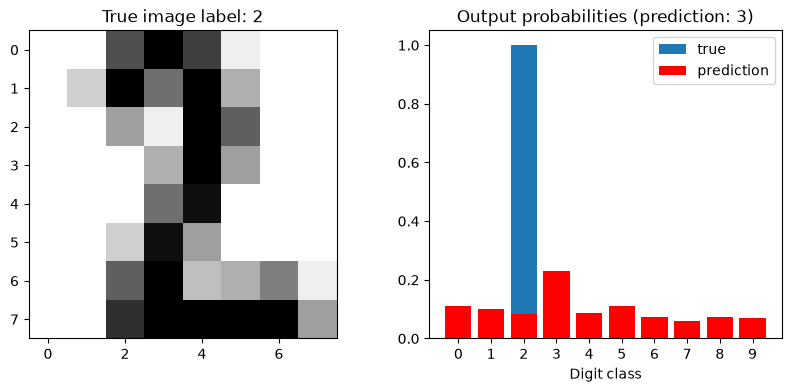

In [25]:
def plot_prediction(model, sample_idx=0, classes=range(10)):
    fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

    ax0.imshow(scaler.inverse_transform(X_test[sample_idx:sample_idx+1]).reshape(8, 8),
               cmap=plt.cm.gray_r, interpolation='nearest')
    ax0.set_title("True image label: %d" % y_test[sample_idx]);


    ax1.bar(classes, one_hot(len(classes), y_test[sample_idx]), label='true')
    ax1.bar(classes, model.forward(X_test[sample_idx]), label='prediction', color="red")
    ax1.set_xticks(classes)
    prediction = model.predict(X_test[sample_idx])
    ax1.set_title('Output probabilities (prediction: %d)'
                  % prediction)
    ax1.set_xlabel('Digit class')
    ax1.legend()

plot_prediction(lr, sample_idx=0)

In [26]:
# Training for one epoch
learning_rate = 0.01

for i, (x, y) in enumerate(zip(X_train, y_train)):
    lr.train(x, y, learning_rate)
    if i % 100 == 0:
        train_loss = lr.loss(X_train, y_train)
        train_acc = lr.accuracy(X_train, y_train)
        test_acc = lr.accuracy(X_test, y_test)
        print("Update #%d, train loss: %0.4f, train acc: %0.3f, test acc: %0.3f"
              % (i, train_loss, train_acc, test_acc))

Update #0, train loss: 2.3578, train acc: 0.118, test acc: 0.107
Update #100, train loss: 1.3101, train acc: 0.695, test acc: 0.700
Update #200, train loss: 0.8665, train acc: 0.847, test acc: 0.874
Update #300, train loss: 0.6396, train acc: 0.902, test acc: 0.919
Update #400, train loss: 0.5341, train acc: 0.907, test acc: 0.915
Update #500, train loss: 0.4644, train acc: 0.919, test acc: 0.922
Update #600, train loss: 0.4073, train acc: 0.924, test acc: 0.930
Update #700, train loss: 0.3707, train acc: 0.933, test acc: 0.937
Update #800, train loss: 0.3496, train acc: 0.935, test acc: 0.941
Update #900, train loss: 0.3245, train acc: 0.936, test acc: 0.944
Update #1000, train loss: 0.3014, train acc: 0.942, test acc: 0.956
Update #1100, train loss: 0.2825, train acc: 0.947, test acc: 0.970
Update #1200, train loss: 0.2692, train acc: 0.948, test acc: 0.963
Update #1300, train loss: 0.2592, train acc: 0.948, test acc: 0.956
Update #1400, train loss: 0.2450, train acc: 0.952, test acc

Evaluate the trained model on the first example:

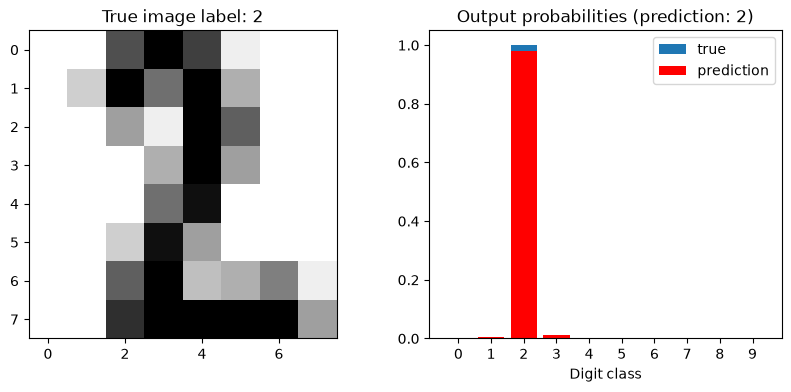

In [27]:
plot_prediction(lr, sample_idx=0)

## b) Feedforward Multilayer

The objective of this section is to implement the backpropagation algorithm (SGD with the chain rule) on a single layer neural network using the sigmoid activation function.

- Implement the `sigmoid` and its element-wise derivative `dsigmoid` functions:

$$
sigmoid(x) = \frac{1}{1 + e^{-x}}
$$

$$
dsigmoid(x) = sigmoid(x) \cdot (1 - sigmoid(x))
$$

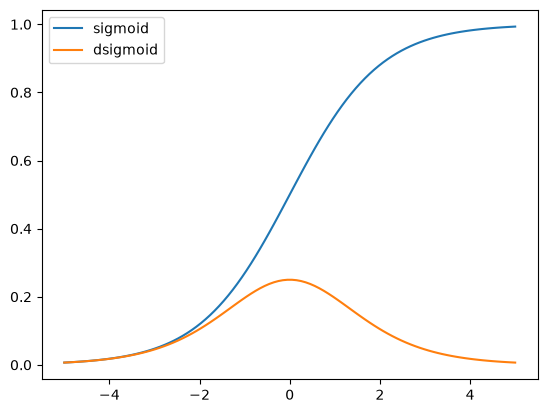

In [28]:
def sigmoid(X):
    return 1. / (1. + np.exp(-X))


def dsigmoid(X):
    sig = sigmoid(X)
    return sig * (1. - sig)


x = np.linspace(-5, 5, 100)
plt.plot(x, sigmoid(x), label='sigmoid')
plt.plot(x, dsigmoid(x), label='dsigmoid')
plt.legend(loc='best');

- Implement `forward` and `forward_keep_all` functions for a model with a hidden layer with a sigmoid activation function:
  - $\mathbf{h} = sigmoid(\mathbf{W}^h \mathbf{x} + \mathbf{b^h})$
  - $\mathbf{y} = softmax(\mathbf{W}^o \mathbf{h} + \mathbf{b^o})$

- Notes:
  - try to keep the code as similar as possible as the previous one;
  - `forward` now has a keep activations parameter to also return hidden activations and pre activations;

- Update the grad function to compute all gradients; check that the gradients are well defined;

- Implement the `train` and `loss` functions.

**Bonus**: reimplementing all from scratch only using the lecture slides but without looking at the solution of the `LogisticRegression` is an excellent exercise.

In [29]:
EPSILON = 1e-8


class NeuralNet():
    """MLP with 1 hidden layer with a sigmoid activation"""

    def __init__(self, input_size, hidden_size, output_size):
        # Small random weights (breaks the symmetry between hidden units),
        # zero biases
        self.W_h = np.random.uniform(size=(input_size, hidden_size),
                                     high=0.01, low=-0.01)
        self.b_h = np.zeros(hidden_size)
        self.W_o = np.random.uniform(size=(hidden_size, output_size),
                                     high=0.01, low=-0.01)
        self.b_o = np.zeros(output_size)
        self.output_size = output_size

    def forward_keep_activations(self, X):
        z_h = np.dot(X, self.W_h) + self.b_h   # hidden pre-activation
        h = sigmoid(z_h)                       # hidden activation
        z_o = np.dot(h, self.W_o) + self.b_o   # output pre-activation (logits)
        y = softmax(z_o)                       # output probabilities
        return y, h, z_h

    def forward(self, X):
        y, h, z_h = self.forward_keep_activations(X)
        return y

    def loss(self, X, y):
        return nll(one_hot(self.output_size, y), self.forward(X))

    def grad_loss(self, x, y_true):
        y, h, z_h = self.forward_keep_activations(x)

        # Output layer: d(nll)/d(z_o) = softmax(z_o) - one_hot(y_true)
        grad_z_o = y - one_hot(self.output_size, y_true)
        grad_W_o = np.outer(h, grad_z_o)
        grad_b_o = grad_z_o

        # Hidden layer: backpropagate through W_o, then through the sigmoid
        grad_h = np.dot(grad_z_o, self.W_o.T)
        grad_z_h = grad_h * dsigmoid(z_h)
        grad_W_h = np.outer(x, grad_z_h)
        grad_b_h = grad_z_h

        return {"W_h": grad_W_h, "b_h": grad_b_h,
                "W_o": grad_W_o, "b_o": grad_b_o}

    def train(self, x, y, learning_rate):
        # Plain SGD update (no momentum)
        grads = self.grad_loss(x, y)
        self.W_h = self.W_h - learning_rate * grads["W_h"]
        self.b_h = self.b_h - learning_rate * grads["b_h"]
        self.W_o = self.W_o - learning_rate * grads["W_o"]
        self.b_o = self.b_o - learning_rate * grads["b_o"]

    def predict(self, X):
        if len(X.shape) == 1:
            return np.argmax(self.forward(X))
        else:
            return np.argmax(self.forward(X), axis=1)

    def accuracy(self, X, y):
        y_preds = np.argmax(self.forward(X), axis=1)
        return np.mean(y_preds == y)

In [30]:
np.random.seed(0)

n_hidden = 10
model = NeuralNet(n_features, n_hidden, n_classes)

### Gradient check

To check that the gradients are well defined, we compare the analytical gradients
returned by `grad_loss` with a numerical approximation by centered finite differences:

$$
\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i + \varepsilon) - L(\theta_i - \varepsilon)}{2 \varepsilon}
$$

The relative error should be very small (around $10^{-7}$ or less).

In [31]:
def numerical_grad(model, x, y, param_name, eps=1e-5):
    """Finite-difference gradient of the single-sample loss w.r.t. one parameter."""
    param = getattr(model, param_name)
    grad = np.zeros_like(param)
    it = np.nditer(param, flags=['multi_index'])
    for _ in it:
        idx = it.multi_index
        old_value = param[idx]
        param[idx] = old_value + eps
        loss_plus = model.loss(x[None, :], np.array([y]))
        param[idx] = old_value - eps
        loss_minus = model.loss(x[None, :], np.array([y]))
        param[idx] = old_value
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad


def relative_error(a, b):
    return np.linalg.norm(a - b) / max(1e-12, np.linalg.norm(a) + np.linalg.norm(b))


check_model = NeuralNet(n_features, n_hidden, n_classes)
# use larger weights than the init so that the check is not trivial
# (but not too large, to avoid a saturated softmax)
for name in ["W_h", "b_h", "W_o", "b_o"]:
    setattr(check_model, name, 0.3 * np.random.normal(size=getattr(check_model, name).shape))

# float64 input for an accurate finite-difference approximation
x_check, y_check = X_train[0].astype(np.float64), y_train[0]
analytical = check_model.grad_loss(x_check, y_check)
for name in ["W_h", "b_h", "W_o", "b_o"]:
    numerical = numerical_grad(check_model, x_check, y_check, name)
    print("%s: shape %s, relative error = %.2e"
          % (name, analytical[name].shape, relative_error(analytical[name], numerical)))

W_h: shape (64, 10), relative error = 8.88e-08
b_h: shape (10,), relative error = 8.87e-08
W_o: shape (10, 10), relative error = 8.88e-08
b_o: shape (10,), relative error = 8.87e-08


In [32]:
model.loss(X_train, y_train)

np.float64(2.3026627937278454)

In [33]:
model.accuracy(X_train, y_train)

np.float64(0.10347085789129011)

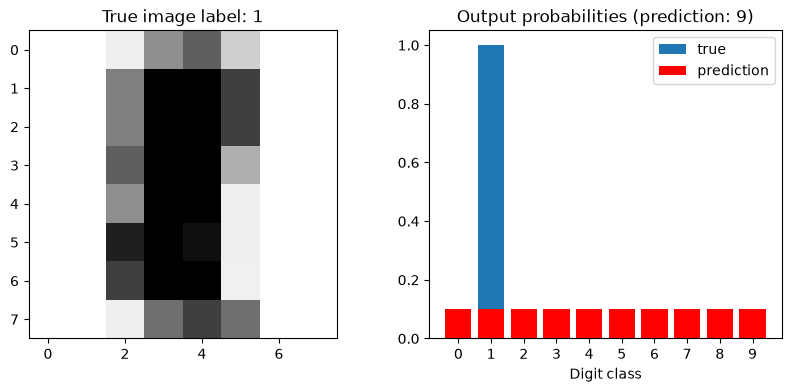

In [34]:
plot_prediction(model, sample_idx=5)

In [35]:
losses, accuracies, accuracies_test = [], [], []
losses.append(model.loss(X_train, y_train))
accuracies.append(model.accuracy(X_train, y_train))
accuracies_test.append(model.accuracy(X_test, y_test))

print("Random init: train loss: %0.5f, train acc: %0.3f, test acc: %0.3f"
      % (losses[-1], accuracies[-1], accuracies_test[-1]))

for epoch in range(15):
    for i, (x, y) in enumerate(zip(X_train, y_train)):
        model.train(x, y, 0.1)

    losses.append(model.loss(X_train, y_train))
    accuracies.append(model.accuracy(X_train, y_train))
    accuracies_test.append(model.accuracy(X_test, y_test))
    print("Epoch #%d, train loss: %0.5f, train acc: %0.3f, test acc: %0.3f"
          % (epoch + 1, losses[-1], accuracies[-1], accuracies_test[-1]))

Random init: train loss: 2.30266, train acc: 0.103, test acc: 0.107
Epoch #1, train loss: 0.41676, train acc: 0.881, test acc: 0.833
Epoch #2, train loss: 0.20127, train acc: 0.962, test acc: 0.907
Epoch #3, train loss: 0.14691, train acc: 0.969, test acc: 0.922


Epoch #4, train loss: 0.11327, train acc: 0.976, test acc: 0.926
Epoch #5, train loss: 0.08979, train acc: 0.982, test acc: 0.944
Epoch #6, train loss: 0.07147, train acc: 0.986, test acc: 0.944
Epoch #7, train loss: 0.05609, train acc: 0.991, test acc: 0.956


Epoch #8, train loss: 0.04427, train acc: 0.993, test acc: 0.948
Epoch #9, train loss: 0.03910, train acc: 0.994, test acc: 0.952
Epoch #10, train loss: 0.03648, train acc: 0.995, test acc: 0.952
Epoch #11, train loss: 0.03209, train acc: 0.996, test acc: 0.959


Epoch #12, train loss: 0.02810, train acc: 0.997, test acc: 0.959
Epoch #13, train loss: 0.02640, train acc: 0.997, test acc: 0.963
Epoch #14, train loss: 0.02381, train acc: 0.998, test acc: 0.967
Epoch #15, train loss: 0.02189, train acc: 0.998, test acc: 0.967


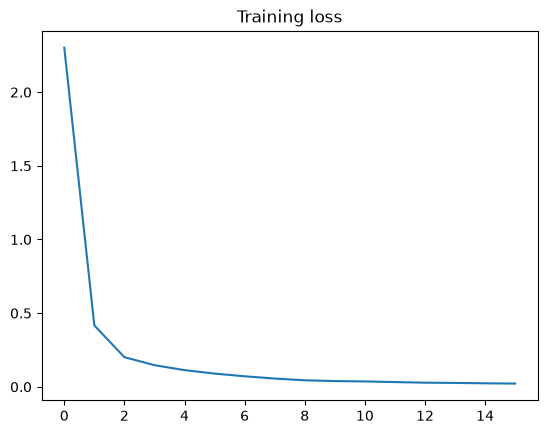

In [36]:
plt.plot(losses)
plt.title("Training loss");

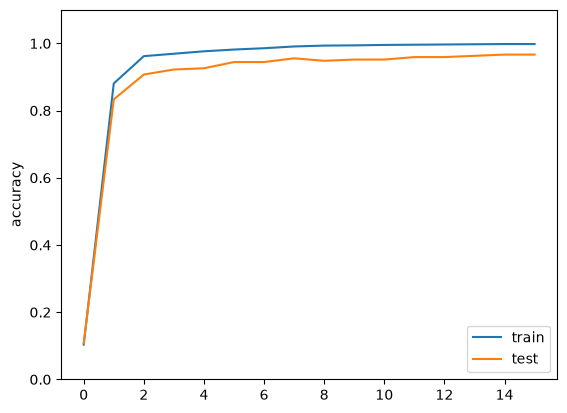

In [37]:
plt.plot(accuracies, label='train')
plt.plot(accuracies_test, label='test')
plt.ylim(0, 1.1)
plt.ylabel("accuracy")
plt.legend(loc='best');

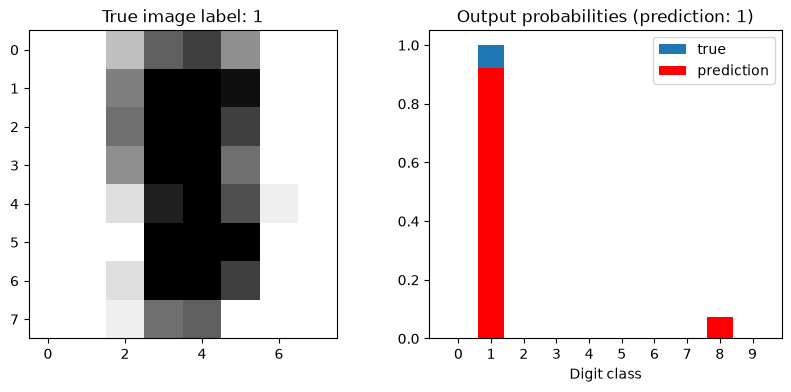

In [38]:
plot_prediction(model, sample_idx=4)

## c) Exercises

### Look at worst prediction errors

- Use numpy to find test samples for which the model made the worst predictions,
- Use the `plot_prediction` to look at the model predictions on those,
- Would you have done any better?

In [39]:
# Probability that the model gives to the *true* class of each test sample
probas_test = model.forward(X_test)
p_true_class = probas_test[np.arange(len(y_test)), y_test]

# The worst predictions are the ones with the lowest probability on the true class
worst_idx = np.argsort(p_true_class)[:5]
for idx in worst_idx:
    print("test sample %3d: true=%d, predicted=%d, p(true class)=%.4f, p(predicted)=%.4f"
          % (idx, y_test[idx], model.predict(X_test[idx]),
             p_true_class[idx], probas_test[idx].max()))

test sample 107: true=5, predicted=9, p(true class)=0.0000, p(predicted)=0.9926
test sample 219: true=4, predicted=7, p(true class)=0.0035, p(predicted)=0.9689
test sample 252: true=8, predicted=3, p(true class)=0.0157, p(predicted)=0.6791
test sample  69: true=8, predicted=5, p(true class)=0.1443, p(predicted)=0.7806
test sample 207: true=5, predicted=9, p(true class)=0.2636, p(predicted)=0.7199


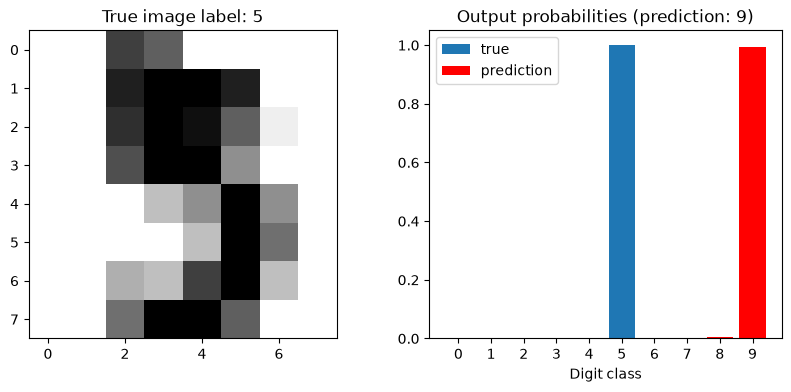

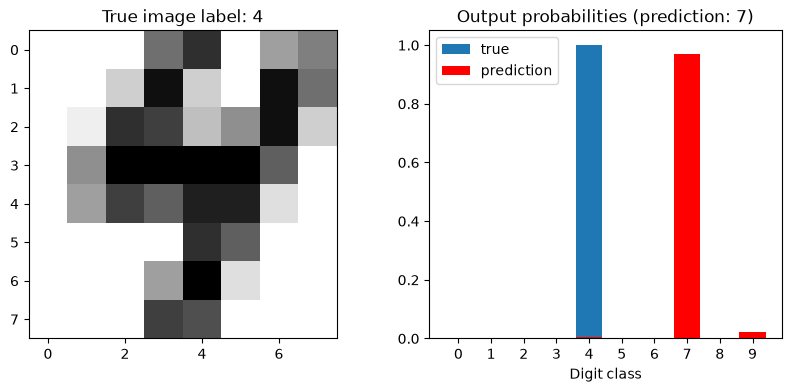

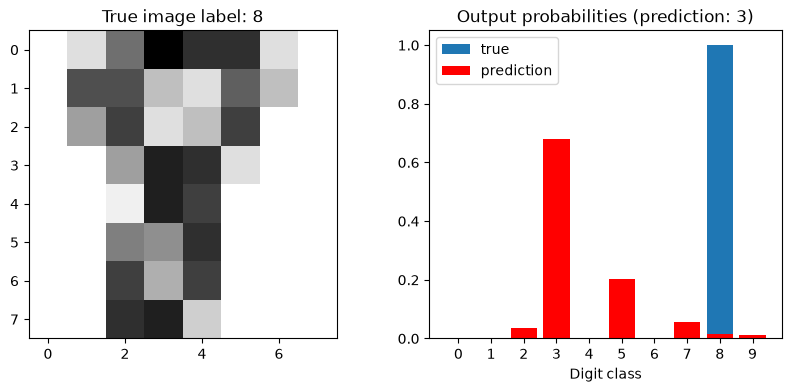

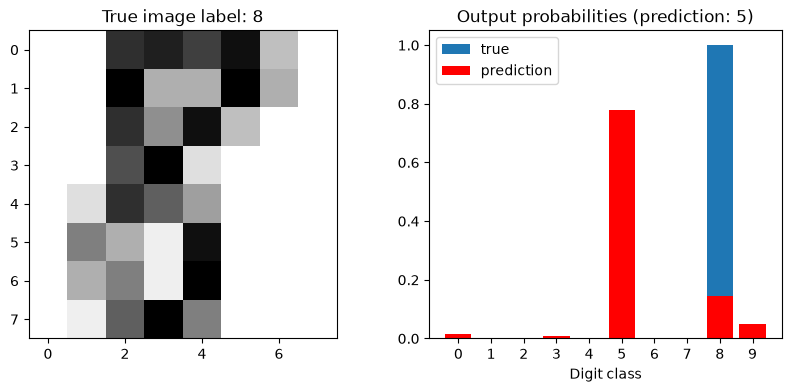

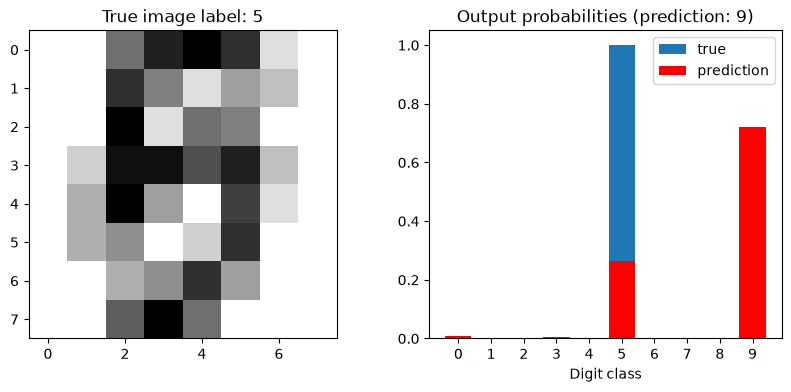

In [40]:
for idx in worst_idx:
    plot_prediction(model, sample_idx=idx)

**Would you have done any better?**

Partly. Some of these errors are understandable: the worst "5" (sample 107) has a closed top loop and a long vertical right stroke, which is very close to a "9" at 8x8 resolution, and the "8" predicted as a "5" (sample 69) is written with a very thin lower loop. A human would probably still recognise the "4" predicted as a "7" (sample 219) and some of the "8"s, so a better model could avoid these errors. Note that the model is **very confident** on its worst mistakes (p = 0.99 on the wrong class for sample 107): the softmax probabilities of a network trained with the NLL are often over-confident and are not reliable confidence scores.

### Hyper parameters settings

- Experiment with different hyper parameters:
  - learning rate,
  - size of hidden layer,
  - initialization scheme: test with 0 initialization vs uniform,
  - implement other activation functions,
  - implement the support for a second hidden layer.

To run all the experiments below (and the mini-batch / momentum ones) we write a more
general version of `NeuralNet`, called `MLP`:

- any number of hidden layers (`layer_sizes=[64, 10, 10]` is the same network as `NeuralNet`),
- the activation function is a parameter (`sigmoid`, `tanh`, `relu`),
- the initialization scheme is a parameter (`uniform`, `zero`, `glorot`),
- `grad_loss` and `train` take a **mini-batch** `X` of shape `(batch_size, n_features)`
  and use the **average** gradient over the batch,
- optional **momentum**.

The backward pass is the same chain rule as in `NeuralNet`, written as a loop over the layers.

In [41]:
def relu(X):
    return np.maximum(0., X)


def drelu(X):
    return (X > 0).astype(X.dtype)


def dtanh(X):
    return 1. - np.tanh(X) ** 2


ACTIVATIONS = {
    "sigmoid": (sigmoid, dsigmoid),
    "tanh": (np.tanh, dtanh),
    "relu": (relu, drelu),
}


class MLP():
    """MLP with any number of hidden layers, trained with mini-batch SGD (+ momentum)."""

    def __init__(self, layer_sizes, activation="sigmoid", init="uniform",
                 init_scale=0.01, momentum=0., seed=None):
        rng = np.random.default_rng(seed)
        self.Ws, self.bs = [], []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            if init == "zero":
                W = np.zeros((n_in, n_out))
            elif init == "uniform":
                W = rng.uniform(-init_scale, init_scale, size=(n_in, n_out))
            elif init == "glorot":
                limit = np.sqrt(6. / (n_in + n_out))
                W = rng.uniform(-limit, limit, size=(n_in, n_out))
            else:
                raise ValueError(init)
            self.Ws.append(W)
            self.bs.append(np.zeros(n_out))
        self.act, self.dact = ACTIVATIONS[activation]
        self.output_size = layer_sizes[-1]
        self.momentum = momentum
        # velocities for momentum
        self.vWs = [np.zeros_like(W) for W in self.Ws]
        self.vbs = [np.zeros_like(b) for b in self.bs]

    def forward_keep_activations(self, X):
        X = np.atleast_2d(X)
        hs, zs = [X], []      # hs[l] = input of layer l, zs[l] = pre-activation of hidden layer l
        h = X
        for W, b in zip(self.Ws[:-1], self.bs[:-1]):
            z = np.dot(h, W) + b
            h = self.act(z)
            zs.append(z)
            hs.append(h)
        y = softmax(np.dot(h, self.Ws[-1]) + self.bs[-1])
        return y, hs, zs

    def forward(self, X):
        y, _, _ = self.forward_keep_activations(X)
        return y if np.ndim(X) > 1 else y[0]

    def loss(self, X, y):
        return nll(one_hot(self.output_size, y), self.forward(X))

    def grad_loss(self, X, y_true):
        X = np.atleast_2d(X)
        y_true = np.atleast_1d(y_true)
        batch_size = X.shape[0]
        y, hs, zs = self.forward_keep_activations(X)

        grads_W = [None] * len(self.Ws)
        grads_b = [None] * len(self.bs)
        # gradient of the *average* nll w.r.t. the logits
        grad_z = (y - one_hot(self.output_size, y_true)) / batch_size
        for l in reversed(range(len(self.Ws))):
            grads_W[l] = np.dot(hs[l].T, grad_z)
            grads_b[l] = np.sum(grad_z, axis=0)
            if l > 0:
                # backprop through W_l then through the activation of layer l-1
                grad_z = np.dot(grad_z, self.Ws[l].T) * self.dact(zs[l - 1])
        return grads_W, grads_b

    def train(self, X, y, learning_rate):
        grads_W, grads_b = self.grad_loss(X, y)
        for l in range(len(self.Ws)):
            # momentum = 0 gives plain SGD
            self.vWs[l] = self.momentum * self.vWs[l] - learning_rate * grads_W[l]
            self.vbs[l] = self.momentum * self.vbs[l] - learning_rate * grads_b[l]
            self.Ws[l] = self.Ws[l] + self.vWs[l]
            self.bs[l] = self.bs[l] + self.vbs[l]

    def grad_norm(self, X, y):
        """Norm of the average gradient on (X, y), all parameters concatenated."""
        grads_W, grads_b = self.grad_loss(X, y)
        return np.sqrt(sum(np.sum(g ** 2) for g in grads_W + grads_b))

    def predict(self, X):
        if len(X.shape) == 1:
            return np.argmax(self.forward(X))
        else:
            return np.argmax(self.forward(X), axis=1)

    def accuracy(self, X, y):
        y_preds = np.argmax(self.forward(X), axis=1)
        return np.mean(y_preds == y)


def fit(model, learning_rate=0.1, n_epochs=15, batch_size=1, seed=0, verbose=False):
    """Train `model` on (X_train, y_train) and return the learning curves."""
    rng = np.random.default_rng(seed)
    history = {"loss": [model.loss(X_train, y_train)],
               "train_acc": [model.accuracy(X_train, y_train)],
               "test_acc": [model.accuracy(X_test, y_test)],
               "grad_norm": [model.grad_norm(X_train, y_train)]}
    for epoch in range(n_epochs):
        perm = rng.permutation(len(X_train))
        for start in range(0, len(X_train), batch_size):
            batch_idx = perm[start:start + batch_size]
            model.train(X_train[batch_idx], y_train[batch_idx], learning_rate)
        history["loss"].append(model.loss(X_train, y_train))
        history["train_acc"].append(model.accuracy(X_train, y_train))
        history["test_acc"].append(model.accuracy(X_test, y_test))
        history["grad_norm"].append(model.grad_norm(X_train, y_train))
        if verbose:
            print("Epoch #%d, train loss: %0.5f, train acc: %0.3f, test acc: %0.3f, grad norm: %0.4f"
                  % (epoch + 1, history["loss"][-1], history["train_acc"][-1],
                     history["test_acc"][-1], history["grad_norm"][-1]))
    return history


def plot_histories(histories, title):
    fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
    for label, h in histories.items():
        ax0.plot(h["loss"], label=label)
        ax1.plot(h["test_acc"], label=label)
    ax0.set_title(title + ": training loss")
    ax0.set_xlabel("epoch")
    ax0.set_yscale("log")
    ax1.set_title(title + ": test accuracy")
    ax1.set_xlabel("epoch")
    ax1.set_ylim(0, 1.05)
    ax0.legend()
    ax1.legend()


def summary(histories):
    for label, h in histories.items():
        print("%-28s final train loss: %0.4f, train acc: %0.3f, test acc: %0.3f"
              % (label, h["loss"][-1], h["train_acc"][-1], h["test_acc"][-1]))

**Sanity checks for `MLP`:** with the same weights, a 1-hidden-layer `MLP` must give
exactly the same gradients as `NeuralNet` on one sample, and the gradients of a
**2-hidden-layer** `MLP` (on a mini-batch) must match finite differences.

In [42]:
# 1) same gradients as NeuralNet
mlp = MLP([n_features, n_hidden, n_classes])
mlp.Ws = [check_model.W_h.copy(), check_model.W_o.copy()]
mlp.bs = [check_model.b_h.copy(), check_model.b_o.copy()]
grads_W, grads_b = mlp.grad_loss(x_check, y_check)
ref = check_model.grad_loss(x_check, y_check)
print("max difference with NeuralNet gradients:",
      max(np.abs(grads_W[0] - ref["W_h"]).max(), np.abs(grads_b[0] - ref["b_h"]).max(),
          np.abs(grads_W[1] - ref["W_o"]).max(), np.abs(grads_b[1] - ref["b_o"]).max()))

# 2) finite differences on a 2-hidden-layer network, mini-batch of 5 samples, tanh
mlp2 = MLP([n_features, 12, 8, n_classes], activation="tanh", init="glorot", seed=1)
Xb, yb = X_train[:5].astype(np.float64), y_train[:5]
grads_W, grads_b = mlp2.grad_loss(Xb, yb)
eps = 1e-5
for l, (W, b) in enumerate(zip(mlp2.Ws, mlp2.bs)):
    for param, grad, name in [(W, grads_W[l], "W%d" % l), (b, grads_b[l], "b%d" % l)]:
        num = np.zeros_like(param)
        it = np.nditer(param, flags=['multi_index'])
        for _ in it:
            idx = it.multi_index
            old = param[idx]
            param[idx] = old + eps
            lp = mlp2.loss(Xb, yb)
            param[idx] = old - eps
            lm = mlp2.loss(Xb, yb)
            param[idx] = old
            num[idx] = (lp - lm) / (2 * eps)
        print("%s: relative error = %.2e" % (name, relative_error(grad, num)))

max difference with NeuralNet gradients: 0.0
W0: relative error = 2.01e-07
b0: relative error = 1.20e-07
W1: relative error = 2.14e-07
b1: relative error = 1.18e-07
W2: relative error = 2.42e-07
b2: relative error = 2.41e-07


#### Learning rate

C:\Users\USER\AppData\Local\Temp\ipykernel_13004\1326083407.py:2: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X))


lr=0.001                     final train loss: 2.2396, train acc: 0.318, test acc: 0.274
lr=0.01                      final train loss: 0.1880, train acc: 0.974, test acc: 0.959
lr=0.1                       final train loss: 0.0212, train acc: 0.997, test acc: 0.974
lr=1                         final train loss: 0.7624, train acc: 0.851, test acc: 0.844
lr=10                        final train loss: 6.9729, train acc: 0.593, test acc: 0.589


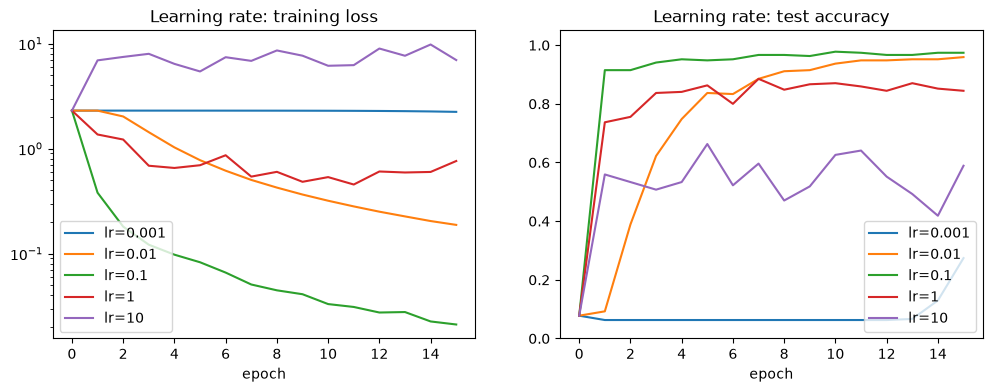

In [43]:
histories = {}
for lr_value in [0.001, 0.01, 0.1, 1., 10.]:
    m = MLP([n_features, 10, n_classes], seed=0)
    histories["lr=%g" % lr_value] = fit(m, learning_rate=lr_value)
summary(histories)
plot_histories(histories, "Learning rate")

**Learning rate.** With per-sample SGD (batch size 1, 15 epochs):
- `lr=0.001` is too small: after 15 epochs the loss has barely moved (train acc around 30%), the model is still close to its random init.
- `lr=0.01` works but converges slowly.
- `lr=0.1` gives the best result (test acc around 97%).
- `lr=1` and `lr=10` are too large: the updates overshoot, the loss oscillates or explodes (with `lr=10` the sigmoid saturates and `np.exp` overflows), and the final accuracy is much worse.

#### Size of the hidden layer

hidden=2                     final train loss: 1.2376, train acc: 0.382, test acc: 0.367
hidden=5                     final train loss: 0.1268, train acc: 0.965, test acc: 0.937
hidden=10                    final train loss: 0.0212, train acc: 0.997, test acc: 0.974
hidden=50                    final train loss: 0.0040, train acc: 1.000, test acc: 0.974
hidden=100                   final train loss: 0.0029, train acc: 1.000, test acc: 0.981


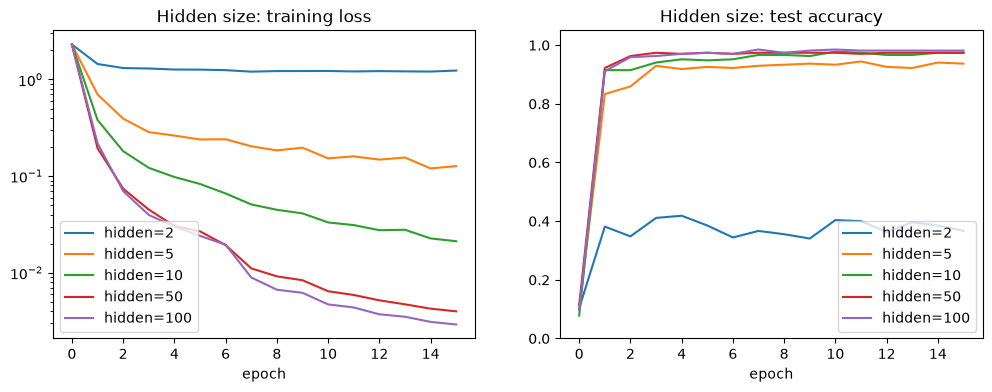

In [44]:
histories = {}
for size in [2, 5, 10, 50, 100]:
    m = MLP([n_features, size, n_classes], seed=0)
    histories["hidden=%d" % size] = fit(m, learning_rate=0.1)
summary(histories)
plot_histories(histories, "Hidden size")

**Hidden layer size.** With only 2 hidden units the network does not have enough capacity (underfitting, test acc around 37%). 5 units already reach about 94%, and 10 units or more give 97 to 98% test accuracy. Larger hidden layers fit the training set perfectly (train loss close to 0) but the test accuracy improves only a little: from 10 units on, extra capacity mostly helps memorise the training set.

#### Initialization: zero vs uniform

init=zero                    final train loss: 1.0292, train acc: 0.540, test acc: 0.493
init=uniform                 final train loss: 0.0212, train acc: 0.997, test acc: 0.974
init=glorot                  final train loss: 0.0177, train acc: 0.999, test acc: 0.967


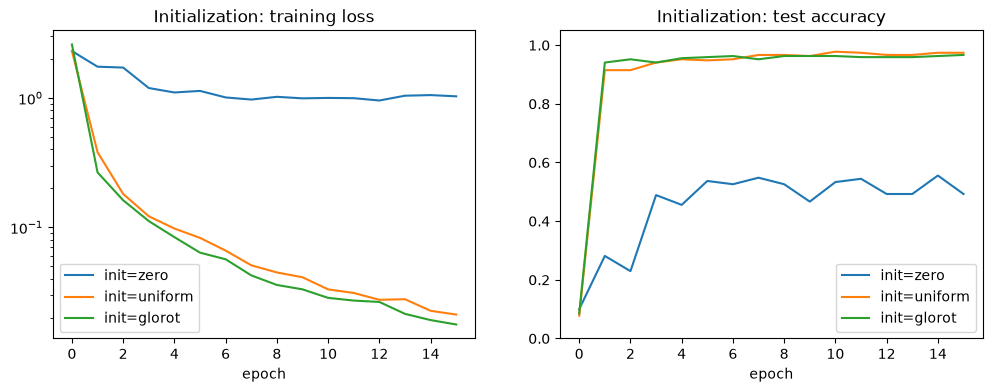

In [45]:
histories = {}
for init in ["zero", "uniform", "glorot"]:
    m = MLP([n_features, 10, n_classes], init=init, seed=0)
    histories["init=%s" % init] = fit(m, learning_rate=0.1)
summary(histories)
plot_histories(histories, "Initialization")

In [46]:
# With zero init all the hidden units compute the same value and, in exact arithmetic,
# receive exactly the same gradient: they should stay identical forever (the network
# behaves as if it had a single hidden unit). Let's measure how different the hidden
# units (= columns of W_h) are, epoch after epoch:
zero_model = MLP([n_features, 10, n_classes], init="zero", seed=0)
for epoch in range(15):
    fit(zero_model, learning_rate=0.1, n_epochs=1, seed=epoch)
    W_h = zero_model.Ws[0]
    print("epoch %2d: max difference between hidden units = %.1e, train acc = %.3f"
          % (epoch + 1, np.abs(W_h - W_h[:, :1]).max(),
             zero_model.accuracy(X_train, y_train)))

epoch  1: max difference between hidden units = 3.4e-10, train acc = 0.309
epoch  2: max difference between hidden units = 3.5e-02, train acc = 0.299
epoch  3: max difference between hidden units = 7.2e-01, train acc = 0.535


epoch  4: max difference between hidden units = 1.0e+00, train acc = 0.531
epoch  5: max difference between hidden units = 1.5e+00, train acc = 0.584
epoch  6: max difference between hidden units = 1.8e+00, train acc = 0.568


epoch  7: max difference between hidden units = 1.9e+00, train acc = 0.562
epoch  8: max difference between hidden units = 1.9e+00, train acc = 0.597
epoch  9: max difference between hidden units = 1.9e+00, train acc = 0.563


epoch 10: max difference between hidden units = 1.9e+00, train acc = 0.623
epoch 11: max difference between hidden units = 2.1e+00, train acc = 0.629
epoch 12: max difference between hidden units = 2.0e+00, train acc = 0.620


epoch 13: max difference between hidden units = 2.2e+00, train acc = 0.648
epoch 14: max difference between hidden units = 2.0e+00, train acc = 0.654


epoch 15: max difference between hidden units = 1.8e+00, train acc = 0.620


**Initialization.** With uniform (or Glorot) random init the network trains well. With **zero init** it learns very badly (train acc around 54%). With all weights at 0, every hidden unit computes the same value and receives exactly the same gradient (**symmetry**), so in exact arithmetic they stay identical forever and the network behaves like a network with a **single** hidden unit.

The trace above shows that in practice the hidden units are identical at the beginning and then slowly drift apart: floating-point rounding in the matrix products (different summation orders) creates tiny differences (around 1e-19) that grow exponentially during training. The symmetry is broken only by numerical noise, much later and much less efficiently than with a random initialization. Note that zero init is fine for the **biases**: the random weights are enough to break the symmetry.

#### Other activation functions

sigmoid lr=0.1               final train loss: 0.0177, train acc: 0.999, test acc: 0.967
tanh lr=0.1                  final train loss: 0.0273, train acc: 0.993, test acc: 0.944
relu lr=0.1                  final train loss: 1.8658, train acc: 0.273, test acc: 0.248
sigmoid lr=0.01              final train loss: 0.1554, train acc: 0.977, test acc: 0.963
tanh lr=0.01                 final train loss: 0.0385, train acc: 0.998, test acc: 0.970
relu lr=0.01                 final train loss: 0.0171, train acc: 1.000, test acc: 0.974


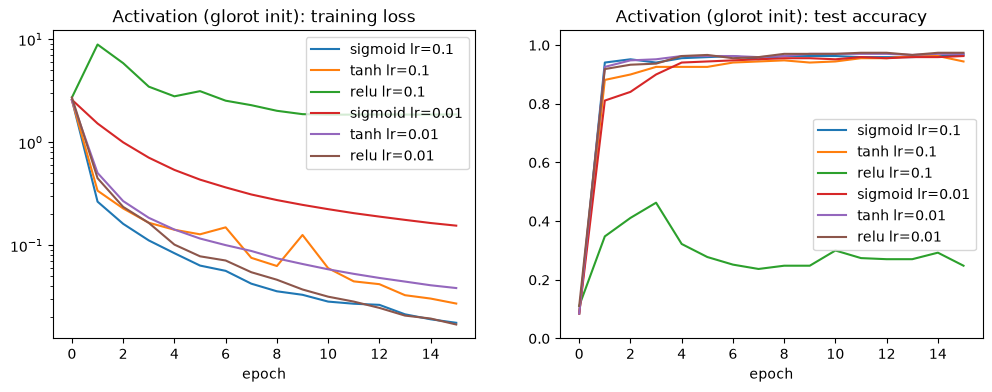

In [47]:
histories = {}
for lr_value in [0.1, 0.01]:
    for activation in ["sigmoid", "tanh", "relu"]:
        m = MLP([n_features, 10, n_classes], activation=activation, init="glorot", seed=0)
        histories["%s lr=%g" % (activation, lr_value)] = fit(m, learning_rate=lr_value)
summary(histories)
plot_histories(histories, "Activation (glorot init)")

**Activation functions.** All three activations reach 96 to 97% test accuracy, but **not with the same learning rate**. With `lr=0.1` and per-sample updates, ReLU diverges: ReLU activations are not bounded, so a few large updates produce large activations and large gradients, and many units end up "dead" (always negative pre-activation, hence zero gradient). With `lr=0.01`, ReLU trains well and converges fast, while the sigmoid is slower at this learning rate because its derivative is at most 0.25. tanh (zero-centered, derivative up to 1) sits in between.

#### Second hidden layer

1 hidden layer [10] sigmoid  final train loss: 0.0177, train acc: 0.999, test acc: 0.967
1 hidden layer [10] relu     final train loss: 0.0171, train acc: 1.000, test acc: 0.974
2 hidden layers [10, 10] sigmoid final train loss: 0.0237, train acc: 0.997, test acc: 0.963
2 hidden layers [10, 10] relu final train loss: 0.0088, train acc: 0.999, test acc: 0.959
2 hidden layers [50, 20] sigmoid final train loss: 0.0038, train acc: 1.000, test acc: 0.985
2 hidden layers [50, 20] relu final train loss: 0.0019, train acc: 1.000, test acc: 0.989


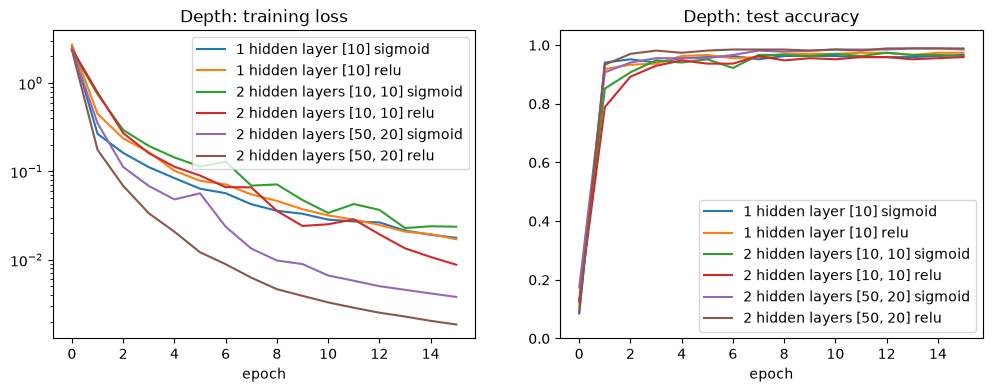

In [48]:
histories = {}
configs = {
    "1 hidden layer [10]": [n_features, 10, n_classes],
    "2 hidden layers [10, 10]": [n_features, 10, 10, n_classes],
    "2 hidden layers [50, 20]": [n_features, 50, 20, n_classes],
}
# learning rate that works best for each activation (see the previous experiment)
best_lr = {"sigmoid": 0.1, "relu": 0.01}
for label, sizes in configs.items():
    for activation in ["sigmoid", "relu"]:
        m = MLP(sizes, activation=activation, init="glorot", seed=0)
        histories["%s %s" % (label, activation)] = fit(m, learning_rate=best_lr[activation])
summary(histories)
plot_histories(histories, "Depth")

**Second hidden layer.** Adding a second hidden layer only required generalising the backward loop (the same chain rule applied once more). On this small and easy dataset it does not help much at equal width ([10, 10] is about the same as [10]); a wider and deeper network ([50, 20]) reaches the best test accuracy (around 98.5 to 99%). The gradient checks above confirm that the gradients of the 2-hidden-layer network are correct.

### Mini-batches

- The current implementations of `train` and `grad_loss` function currently only accept a single sample at a time:
    - implement the support for training with a mini-batch of 32 samples at a time instead of one,
    - experiment with different sizes of batches,
    - monitor the norm of the average gradients on the full training set at the end of each epoch.

`MLP.grad_loss` / `MLP.train` already accept mini-batches (see above): the gradient is
averaged over the samples of the batch. `fit` records the norm of the average gradient on the
full training set at the end of each epoch (`history["grad_norm"]`).

In [49]:
m = MLP([n_features, 10, n_classes], seed=0)
h32 = fit(m, learning_rate=0.5, batch_size=32, n_epochs=15, verbose=True)

Epoch #1, train loss: 2.24590, train acc: 0.166, test acc: 0.178, grad norm: 0.1744
Epoch #2, train loss: 1.43204, train acc: 0.615, test acc: 0.552, grad norm: 0.1908
Epoch #3, train loss: 0.85893, train acc: 0.830, test acc: 0.800, grad norm: 0.1322
Epoch #4, train loss: 0.59103, train acc: 0.894, test acc: 0.878, grad norm: 0.0946
Epoch #5, train loss: 0.45133, train acc: 0.927, test acc: 0.930, grad norm: 0.0892
Epoch #6, train loss: 0.36269, train acc: 0.920, test acc: 0.926, grad norm: 0.0843
Epoch #7, train loss: 0.29257, train acc: 0.947, test acc: 0.930, grad norm: 0.0553
Epoch #8, train loss: 0.24614, train acc: 0.958, test acc: 0.956, grad norm: 0.0494
Epoch #9, train loss: 0.21073, train acc: 0.966, test acc: 0.952, grad norm: 0.0383
Epoch #10, train loss: 0.18523, train acc: 0.973, test acc: 0.963, grad norm: 0.0339
Epoch #11, train loss: 0.16680, train acc: 0.975, test acc: 0.948, grad norm: 0.0362
Epoch #12, train loss: 0.15073, train acc: 0.980, test acc: 0.956, grad no

batch=1                      final train loss: 0.0288, train acc: 0.993, test acc: 0.944
batch=8                      final train loss: 0.0102, train acc: 1.000, test acc: 0.978
batch=32                     final train loss: 0.0597, train acc: 0.995, test acc: 0.959
batch=128                    final train loss: 0.2516, train acc: 0.965, test acc: 0.952
full batch                   final train loss: 2.2961, train acc: 0.109, test acc: 0.063


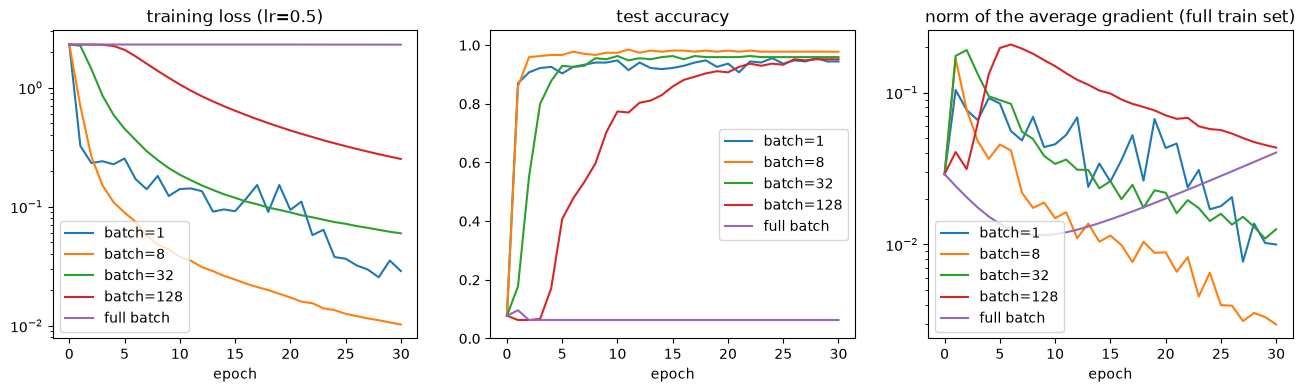

In [50]:
histories = {}
n_epochs_mb = 30
for batch_size in [1, 8, 32, 128, len(X_train)]:
    m = MLP([n_features, 10, n_classes], seed=0)
    label = "batch=%d" % batch_size if batch_size < len(X_train) else "full batch"
    histories[label] = fit(m, learning_rate=0.5, batch_size=batch_size, n_epochs=n_epochs_mb)
summary(histories)

fig, (ax0, ax1, ax2) = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for label, h in histories.items():
    ax0.plot(h["loss"], label=label)
    ax1.plot(h["test_acc"], label=label)
    ax2.plot(h["grad_norm"], label=label)
ax0.set_title("training loss (lr=0.5)"); ax0.set_yscale("log"); ax0.set_xlabel("epoch")
ax1.set_title("test accuracy"); ax1.set_ylim(0, 1.05); ax1.set_xlabel("epoch")
ax2.set_title("norm of the average gradient (full train set)"); ax2.set_yscale("log")
ax2.set_xlabel("epoch")
ax0.legend(); ax1.legend(); ax2.legend();

**Mini-batches.** With the gradient **averaged** over the batch, the same learning rate (0.5) means:
- **batch=1**: many noisy updates per epoch. The loss decreases fast but noisily, and the noise of the gradient keeps the gradient norm from going to 0.
- **batch=8 / 32**: a good trade-off. Updates are less noisy and much faster to compute (vectorised), and the loss converges well.
- **batch=128 / full batch**: very few updates per epoch (12, or only 1 with full batch), so after 30 epochs the network has made too few steps and is still far from convergence. With bigger batches the learning rate (or the number of epochs) must be increased.

The norm of the average gradient on the full training set decreases during training: it shows how close the parameters are to a stationary point of the training loss.

### Momentum

- Bonus: Implement momentum

`MLP.train` implements the classical momentum update:

$$
v \leftarrow \mu \, v - \eta \, \nabla_\theta L \qquad \theta \leftarrow \theta + v
$$

momentum=0                   final train loss: 0.3381, train acc: 0.942, test acc: 0.944
momentum=0.5                 final train loss: 0.1401, train acc: 0.982, test acc: 0.959
momentum=0.9                 final train loss: 0.0330, train acc: 0.997, test acc: 0.959


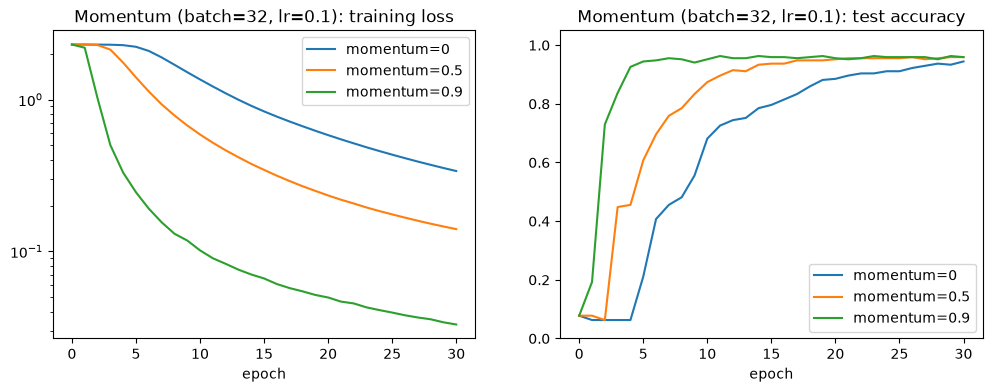

In [51]:
histories = {}
for mu in [0., 0.5, 0.9]:
    m = MLP([n_features, 10, n_classes], momentum=mu, seed=0)
    histories["momentum=%g" % mu] = fit(m, learning_rate=0.1, batch_size=32, n_epochs=30)
summary(histories)
plot_histories(histories, "Momentum (batch=32, lr=0.1)")

**Momentum.** With the same learning rate and batch size, momentum speeds up training a lot: after 30 epochs the training loss is 0.34 without momentum, 0.14 with mu=0.5 and 0.03 with mu=0.9. Momentum accumulates the gradients of the previous steps, so it accelerates in directions where the gradient is consistent and dampens the oscillations. With mu=0.9 the effective learning rate is about lr/(1-mu) = 10 x lr.

### Back to Keras

- Implement the same network architecture with Keras;

- Check that the Keras model can approximately reproduce the behavior of the Numpy model when using similar hyperparameter values (size of the model, type of activations, learning rate value and use of momentum);

- Compute the negative log likelihood of a sample 42 in the test set (can use `model.predict_proba`);

- Compute the average negative log-likelihood on the full test set.

- Compute the average negative log-likelihood  on the full training set and check that you can get the value of the loss reported by Keras.

- Is the model overfitting or underfitting? (ensure that the model has fully converged by increasing the number of epochs to 50 or more if necessary).

We use the same settings for both models: 1 hidden layer of 10 sigmoid units, softmax output,
uniform init in $[-0.01, 0.01]$ with zero biases, SGD with learning rate 0.1, momentum 0.9,
mini-batches of 32, 60 epochs.

Keras : final train loss 0.0170, train acc 0.999, test acc 0.959
Numpy : final train loss 0.0166, train acc 0.999, test acc 0.959


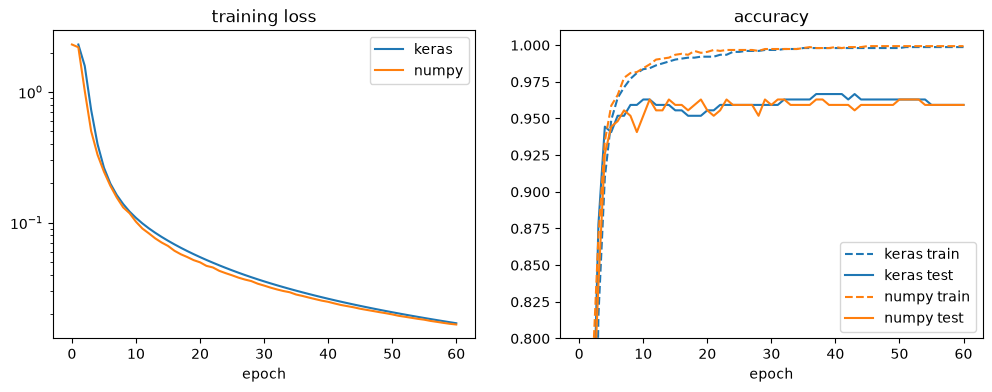

In [52]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(0)

keras_hidden, keras_lr, keras_momentum, keras_batch, keras_epochs = 10, 0.1, 0.9, 32, 60
init = keras.initializers.RandomUniform(minval=-0.01, maxval=0.01, seed=0)

keras_model = keras.Sequential([
    keras.Input(shape=(n_features,)),
    keras.layers.Dense(keras_hidden, activation="sigmoid",
                       kernel_initializer=init, bias_initializer="zeros"),
    keras.layers.Dense(n_classes, activation="softmax",
                       kernel_initializer=init, bias_initializer="zeros"),
])
keras_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=keras_lr, momentum=keras_momentum),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])

keras_history = keras_model.fit(X_train, y_train, batch_size=keras_batch,
                                epochs=keras_epochs, validation_data=(X_test, y_test),
                                verbose=0)

# Same configuration with the numpy MLP
numpy_model = MLP([n_features, keras_hidden, n_classes], activation="sigmoid",
                  init="uniform", init_scale=0.01, momentum=keras_momentum, seed=0)
numpy_history = fit(numpy_model, learning_rate=keras_lr, batch_size=keras_batch,
                    n_epochs=keras_epochs)

print("Keras : final train loss %.4f, train acc %.3f, test acc %.3f"
      % (keras_history.history["loss"][-1], keras_history.history["accuracy"][-1],
         keras_history.history["val_accuracy"][-1]))
print("Numpy : final train loss %.4f, train acc %.3f, test acc %.3f"
      % (numpy_history["loss"][-1], numpy_history["train_acc"][-1],
         numpy_history["test_acc"][-1]))

fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
# Keras reports the running average of the loss during each epoch,
# numpy_history the loss at the end of each epoch (index 0 = before training)
ax0.plot(range(1, keras_epochs + 1), keras_history.history["loss"], label="keras")
ax0.plot(range(0, keras_epochs + 1), numpy_history["loss"], label="numpy")
ax0.set_yscale("log"); ax0.set_title("training loss"); ax0.set_xlabel("epoch"); ax0.legend()
ax1.plot(range(1, keras_epochs + 1), keras_history.history["accuracy"], "C0--", label="keras train")
ax1.plot(range(1, keras_epochs + 1), keras_history.history["val_accuracy"], "C0", label="keras test")
ax1.plot(numpy_history["train_acc"], "C1--", label="numpy train")
ax1.plot(numpy_history["test_acc"], "C1", label="numpy test")
ax1.set_ylim(0.8, 1.01); ax1.set_title("accuracy"); ax1.set_xlabel("epoch"); ax1.legend();

In [53]:
# `predict_proba` was removed from recent Keras versions: `predict` returns the
# softmax probabilities since the last layer has a softmax activation
probas_test_keras = keras_model.predict(X_test, verbose=0)
probas_train_keras = keras_model.predict(X_train, verbose=0)

# NLL of the test sample 42
sample = 42
print("test sample 42: true class %d, p(true class) = %.4f, NLL = %.4f"
      % (y_test[sample], probas_test_keras[sample, y_test[sample]],
         -np.log(probas_test_keras[sample, y_test[sample]])))
# same thing with our nll function
print("with nll(): %.4f" % nll(one_hot(n_classes, y_test[sample]), probas_test_keras[sample]))

# Average NLL on the full test set and on the full training set
test_nll = nll(one_hot(n_classes, y_test), probas_test_keras)
train_nll = nll(one_hot(n_classes, y_train), probas_train_keras)
print("average NLL on the test set : %.4f" % test_nll)
print("average NLL on the train set: %.4f" % train_nll)

# Loss reported by Keras on the full train / test sets
keras_train_loss, keras_train_acc = keras_model.evaluate(X_train, y_train, verbose=0)
keras_test_loss, keras_test_acc = keras_model.evaluate(X_test, y_test, verbose=0)
print("Keras evaluate() train loss : %.4f (acc %.3f)" % (keras_train_loss, keras_train_acc))
print("Keras evaluate() test loss  : %.4f (acc %.3f)" % (keras_test_loss, keras_test_acc))
print("Last value of the loss shown by fit(): %.4f" % keras_history.history["loss"][-1])

test sample 42: true class 8, p(true class) = 0.9994, NLL = 0.0006
with nll(): 0.0006
average NLL on the test set : 0.1190
average NLL on the train set: 0.0161
Keras evaluate() train loss : 0.0161 (acc 0.999)
Keras evaluate() test loss  : 0.1190 (acc 0.959)
Last value of the loss shown by fit(): 0.0170


**Comparison and conclusions.**

- With the same architecture, initialization, learning rate, momentum, batch size and number of epochs, the Keras model and our numpy `MLP` behave almost identically (final train loss 0.017 in both cases, same accuracies). The small differences come from the shuffling order of the mini-batches and float32 (Keras) vs float64 (numpy) computations.
- `predict_proba` no longer exists in recent Keras versions: `predict` already returns the softmax probabilities. The NLL of test sample 42 is -log(p(true class)) (about 0.0006: this sample is predicted correctly with high confidence).
- The average NLL computed with our `nll` function on the full training set **is exactly the loss returned by `keras_model.evaluate`** (same for the test set). The last loss displayed by `fit` is slightly different: it is the average of the losses of the mini-batches **during** the last epoch, while the weights were still changing.
- **Overfitting or underfitting?** The model is **not underfitting**: after 60 epochs it fits the training set almost perfectly (train acc 99.9%, train NLL 0.016). It **overfits slightly**: the test NLL (0.12) is about 7 times larger than the train NLL and the test accuracy (about 96%) is below the train accuracy. The gap is moderate, and the test accuracy stays high. Regularization (L2, early stopping, dropout) or more data could reduce this gap.